In [5]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\sjune\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("misrakahmed/vegetable-image-dataset")

print("Path to dataset files:", path)

c:\Users\sjune\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\sjune\.cache\kagglehub\datasets\misrakahmed\vegetable-image-dataset\versions\1


# 데이터 전처리

In [6]:
from pathlib import Path
import json

import numpy as np
from PIL import Image
from scipy.stats import loguniform, randint, uniform
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import accuracy_score
from sklearn.model_selection import ParameterSampler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
N_RANDOM_CONFIGS = 10
TOP_N = 5
PARAM_RESULTS_PATH = Path("best_5_model_params.json")

dataset_dir = Path(path) / "Vegetable Images"
image_size = (16, 16)
class_names = sorted(folder.name for folder in (dataset_dir / "train").iterdir() if folder.is_dir())
class_to_index = {name: index for index, name in enumerate(class_names)}


def load_split(split):
    features = []
    labels = []
    for class_name in class_names:
        class_dir = dataset_dir / split / class_name
        for image_path in sorted(class_dir.iterdir()):
            if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            with Image.open(image_path) as image:
                resized = image.convert("RGB").resize(image_size, Image.Resampling.BILINEAR)
                features.append(np.asarray(resized, dtype=np.float32).reshape(-1) / 255.0)
            labels.append(class_to_index[class_name])
    return np.asarray(features, dtype=np.float32), np.asarray(labels, dtype=np.int64)


X_train, y_train = load_split("train")
X_validation, y_validation = load_split("validation")
X_test, y_test = load_split("test")
best_five_parameters = {}


def build_model(model_name, params):
    params = params.copy()
    if model_name == "Logistic Regression":
        return make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED, **params))
    if model_name == "k-NN":
        return make_pipeline(StandardScaler(), KNeighborsClassifier(n_jobs=-1, **params))
    if model_name == "SVM":
        return make_pipeline(StandardScaler(), SVC(**params))
    if model_name == "Decision Tree":
        return DecisionTreeClassifier(random_state=SEED, **params)
    if model_name == "Random Forest":
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    if model_name == "Bagging Classifier":
        base_depth = params.pop("base_max_depth")
        base_tree = DecisionTreeClassifier(max_depth=base_depth, random_state=SEED)
        return BaggingClassifier(estimator=base_tree, random_state=SEED, n_jobs=-1, **params)
    if model_name == "Extra Trees":
        return ExtraTreesClassifier(random_state=SEED, n_jobs=-1, **params)
    if model_name == "AdaBoost":
        base_depth = params.pop("base_max_depth")
        base_tree = DecisionTreeClassifier(max_depth=base_depth, random_state=SEED)
        return AdaBoostClassifier(estimator=base_tree, random_state=SEED, **params)
    if model_name == "Gradient Boosting":
        return GradientBoostingClassifier(random_state=SEED, **params)
    if model_name == "Perceptron":
        return make_pipeline(StandardScaler(), Perceptron(random_state=SEED, **params))
    if model_name == "MLP":
        return make_pipeline(
            StandardScaler(),
            MLPClassifier(random_state=SEED, early_stopping=True, **params),
        )
    if model_name == "DNN":
        return make_pipeline(
            StandardScaler(),
            MLPClassifier(random_state=SEED, early_stopping=True, **params),
        )
    raise ValueError(f"Unknown model: {model_name}")


def train_candidates(model_name, parameter_sets, models):
    if len(parameter_sets) != len(models):
        raise ValueError("The number of parameter sets and models must match.")

    scored_candidates = []
    for params, model in zip(parameter_sets, models):
        model.fit(X_train, y_train)
        validation_accuracy = accuracy_score(y_validation, model.predict(X_validation))
        print(f"{model_name} | params={params} | validation_accuracy={validation_accuracy:.4f}")
        scored_candidates.append({
            "params": params.copy(),
            "validation_accuracy": float(validation_accuracy),
            "model": model,
        })

    top_candidates = sorted(
        scored_candidates,
        key=lambda candidate: candidate["validation_accuracy"],
        reverse=True,
    )[:TOP_N]

    saved_candidates = []
    for rank, candidate in enumerate(top_candidates, start=1):
        test_accuracy = accuracy_score(y_test, candidate["model"].predict(X_test))
        saved_candidate = {
            "params": candidate["params"],
            "validation_accuracy": candidate["validation_accuracy"],
            "test_accuracy": float(test_accuracy),
        }
        saved_candidates.append(saved_candidate)
        print(
            f"  Top {rank}: params={saved_candidate['params']} | "
            f"test_accuracy={test_accuracy:.4f}"
        )

    best_five_parameters[model_name] = saved_candidates
    PARAM_RESULTS_PATH.write_text(
        json.dumps(best_five_parameters, ensure_ascii=False, indent=2, default=lambda value: value.item()),
        encoding="utf-8",
    )
    print(f"Top {len(saved_candidates)} saved to {PARAM_RESULTS_PATH.resolve()}")
    print()


## Hyperparameter search

? ??? ?? ?? ??? ???/??? ????? ?? ??? ??????? ?? ????, ??? ????? ?? ? ?? ?????. validation ???? ?? 5?? ????, ??? ??? test ??? ??? ?? ?????. ????? ??? `best_5_model_params.json`? ?????. ?? ??? ?? `N_RANDOM_CONFIGS`? ?? ? ????.

In [7]:
PARAMETER_SEED = int(np.random.SeedSequence().generate_state(1)[0])
print(f"Parameter generation seed: {PARAMETER_SEED}")

Parameter generation seed: 4214800014


# Logistic Regression

In [10]:
logistic_param_sets = list(
    ParameterSampler(
        {"C": loguniform(1e-3, 1e3), "max_iter": randint(500, 2001)},
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(logistic_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'C': np.float64(0.46737903782076806), 'max_iter': 1358}
Combination 2: {'C': np.float64(0.25202399872719894), 'max_iter': 515}
Combination 3: {'C': np.float64(322.392573697727), 'max_iter': 574}
Combination 4: {'C': np.float64(14.823164249718), 'max_iter': 1658}
Combination 5: {'C': np.float64(220.38424584947168), 'max_iter': 860}
Combination 6: {'C': np.float64(0.10477323365227816), 'max_iter': 667}
Combination 7: {'C': np.float64(0.6041468348066917), 'max_iter': 1639}
Combination 8: {'C': np.float64(0.0025692953661737134), 'max_iter': 789}
Combination 9: {'C': np.float64(37.3969376838775), 'max_iter': 1885}
Combination 10: {'C': np.float64(0.3502718917554013), 'max_iter': 1553}


In [11]:
candidate_models = [
    build_model("Logistic Regression", params) for params in logistic_param_sets
]
print("Logistic Regression: created", len(candidate_models), "models")

Logistic Regression: created 10 models


In [12]:
train_candidates("Logistic Regression", logistic_param_sets, candidate_models)
del candidate_models, logistic_param_sets

Logistic Regression | params={'C': np.float64(0.46737903782076806), 'max_iter': 1358} | validation_accuracy=0.6693
Logistic Regression | params={'C': np.float64(0.25202399872719894), 'max_iter': 515} | validation_accuracy=0.6730


c:\Users\sjune\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression | params={'C': np.float64(322.392573697727), 'max_iter': 574} | validation_accuracy=0.6353
Logistic Regression | params={'C': np.float64(14.823164249718), 'max_iter': 1658} | validation_accuracy=0.6243


c:\Users\sjune\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression | params={'C': np.float64(220.38424584947168), 'max_iter': 860} | validation_accuracy=0.6200
Logistic Regression | params={'C': np.float64(0.10477323365227816), 'max_iter': 667} | validation_accuracy=0.6737
Logistic Regression | params={'C': np.float64(0.6041468348066917), 'max_iter': 1639} | validation_accuracy=0.6697
Logistic Regression | params={'C': np.float64(0.0025692953661737134), 'max_iter': 789} | validation_accuracy=0.6450
Logistic Regression | params={'C': np.float64(37.3969376838775), 'max_iter': 1885} | validation_accuracy=0.6173
Logistic Regression | params={'C': np.float64(0.3502718917554013), 'max_iter': 1553} | validation_accuracy=0.6747
  Top 1: params={'C': np.float64(0.3502718917554013), 'max_iter': 1553} | test_accuracy=0.6713
  Top 2: params={'C': np.float64(0.10477323365227816), 'max_iter': 667} | test_accuracy=0.6727
  Top 3: params={'C': np.float64(0.25202399872719894), 'max_iter': 515} | test_accuracy=0.6707
  Top 4: params={'C': np.float64

# k-Nearest Neighbors (k-NN)

In [13]:
knn_param_sets = list(
    ParameterSampler(
        {"n_neighbors": randint(3, 21), "weights": ["uniform", "distance"], "p": randint(1, 3)},
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(knn_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'n_neighbors': 18, 'p': 1, 'weights': 'uniform'}
Combination 2: {'n_neighbors': 18, 'p': 1, 'weights': 'distance'}
Combination 3: {'n_neighbors': 13, 'p': 2, 'weights': 'uniform'}
Combination 4: {'n_neighbors': 9, 'p': 2, 'weights': 'distance'}
Combination 5: {'n_neighbors': 11, 'p': 1, 'weights': 'distance'}
Combination 6: {'n_neighbors': 10, 'p': 2, 'weights': 'uniform'}
Combination 7: {'n_neighbors': 17, 'p': 1, 'weights': 'distance'}
Combination 8: {'n_neighbors': 8, 'p': 1, 'weights': 'uniform'}
Combination 9: {'n_neighbors': 12, 'p': 2, 'weights': 'distance'}
Combination 10: {'n_neighbors': 17, 'p': 2, 'weights': 'uniform'}


In [14]:
candidate_models = [
    build_model("k-NN", params) for params in knn_param_sets
]
print("k-NN: created", len(candidate_models), "models")

k-NN: created 10 models


In [15]:
train_candidates("k-NN", knn_param_sets, candidate_models)
del candidate_models, knn_param_sets

k-NN | params={'n_neighbors': 18, 'p': 1, 'weights': 'uniform'} | validation_accuracy=0.7297
k-NN | params={'n_neighbors': 18, 'p': 1, 'weights': 'distance'} | validation_accuracy=0.7810
k-NN | params={'n_neighbors': 13, 'p': 2, 'weights': 'uniform'} | validation_accuracy=0.7187
k-NN | params={'n_neighbors': 9, 'p': 2, 'weights': 'distance'} | validation_accuracy=0.7987
k-NN | params={'n_neighbors': 11, 'p': 1, 'weights': 'distance'} | validation_accuracy=0.8267
k-NN | params={'n_neighbors': 10, 'p': 2, 'weights': 'uniform'} | validation_accuracy=0.7467
k-NN | params={'n_neighbors': 17, 'p': 1, 'weights': 'distance'} | validation_accuracy=0.7847
k-NN | params={'n_neighbors': 8, 'p': 1, 'weights': 'uniform'} | validation_accuracy=0.8123
k-NN | params={'n_neighbors': 12, 'p': 2, 'weights': 'distance'} | validation_accuracy=0.7730
k-NN | params={'n_neighbors': 17, 'p': 2, 'weights': 'uniform'} | validation_accuracy=0.6753
  Top 1: params={'n_neighbors': 11, 'p': 1, 'weights': 'distance'} 

# Support Vector Machine (SVM)

In [16]:
svm_param_sets = list(
    ParameterSampler(
        {"C": loguniform(1e-2, 1e3), "gamma": loguniform(1e-5, 1e-1), "kernel": ["rbf"]},
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(svm_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'C': np.float64(1.6777388393177377), 'gamma': np.float64(0.0008544397929536556), 'kernel': 'rbf'}
Combination 2: {'C': np.float64(363.98286310133926), 'gamma': np.float64(0.04701719177558555), 'kernel': 'rbf'}
Combination 3: {'C': np.float64(34.881044844591194), 'gamma': np.float64(0.006034305320476808), 'kernel': 'rbf'}
Combination 4: {'C': np.float64(961.4375218857606), 'gamma': np.float64(0.0012564327892794409), 'kernel': 'rbf'}
Combination 5: {'C': np.float64(94.25660090175117), 'gamma': np.float64(0.0001330435200932225), 'kernel': 'rbf'}
Combination 6: {'C': np.float64(2.0778718224822565), 'gamma': np.float64(0.014778005946808687), 'kernel': 'rbf'}
Combination 7: {'C': np.float64(55.787250575909205), 'gamma': np.float64(0.01118297516548339), 'kernel': 'rbf'}
Combination 8: {'C': np.float64(1.259616932638749), 'gamma': np.float64(4.4153538323220136e-05), 'kernel': 'rbf'}
Combination 9: {'C': np.float64(111.19686098469766), 'gamma': 

In [17]:
candidate_models = [
    build_model("SVM", params) for params in svm_param_sets
]
print("SVM: created", len(candidate_models), "models")

SVM: created 10 models


In [18]:
train_candidates("SVM", svm_param_sets, candidate_models)
del candidate_models, svm_param_sets

SVM | params={'C': np.float64(1.6777388393177377), 'gamma': np.float64(0.0008544397929536556), 'kernel': 'rbf'} | validation_accuracy=0.9153
SVM | params={'C': np.float64(363.98286310133926), 'gamma': np.float64(0.04701719177558555), 'kernel': 'rbf'} | validation_accuracy=0.4833
SVM | params={'C': np.float64(34.881044844591194), 'gamma': np.float64(0.006034305320476808), 'kernel': 'rbf'} | validation_accuracy=0.9150
SVM | params={'C': np.float64(961.4375218857606), 'gamma': np.float64(0.0012564327892794409), 'kernel': 'rbf'} | validation_accuracy=0.9480
SVM | params={'C': np.float64(94.25660090175117), 'gamma': np.float64(0.0001330435200932225), 'kernel': 'rbf'} | validation_accuracy=0.9110
SVM | params={'C': np.float64(2.0778718224822565), 'gamma': np.float64(0.014778005946808687), 'kernel': 'rbf'} | validation_accuracy=0.7097
SVM | params={'C': np.float64(55.787250575909205), 'gamma': np.float64(0.01118297516548339), 'kernel': 'rbf'} | validation_accuracy=0.7703
SVM | params={'C': np

# Decision Tree

In [19]:
decision_tree_param_sets = list(
    ParameterSampler(
        {
            "criterion": ["gini", "entropy"],
            "max_depth": randint(3, 51),
            "min_samples_leaf": randint(1, 11),
            "max_features": uniform(0.3, 0.7),
        },
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(decision_tree_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'criterion': 'entropy', 'max_depth': 33, 'max_features': np.float64(0.6380442565692083), 'min_samples_leaf': 3}
Combination 2: {'criterion': 'entropy', 'max_depth': 45, 'max_features': np.float64(0.48438184183808064), 'min_samples_leaf': 1}
Combination 3: {'criterion': 'gini', 'max_depth': 36, 'max_features': np.float64(0.7309123669296774), 'min_samples_leaf': 8}
Combination 4: {'criterion': 'entropy', 'max_depth': 37, 'max_features': np.float64(0.8546827714727194), 'min_samples_leaf': 2}
Combination 5: {'criterion': 'entropy', 'max_depth': 8, 'max_features': np.float64(0.5940333886125193), 'min_samples_leaf': 10}
Combination 6: {'criterion': 'entropy', 'max_depth': 40, 'max_features': np.float64(0.48590207748087033), 'min_samples_leaf': 1}
Combination 7: {'criterion': 'gini', 'max_depth': 26, 'max_features': np.float64(0.5757841555983454), 'min_samples_leaf': 7}
Combination 8: {'criterion': 'gini', 'max_depth': 21, 'max_features': np.f

In [20]:
candidate_models = [
    build_model("Decision Tree", params) for params in decision_tree_param_sets
]
print("Decision Tree: created", len(candidate_models), "models")

Decision Tree: created 10 models


In [21]:
train_candidates("Decision Tree", decision_tree_param_sets, candidate_models)
del candidate_models, decision_tree_param_sets

Decision Tree | params={'criterion': 'entropy', 'max_depth': 33, 'max_features': np.float64(0.6380442565692083), 'min_samples_leaf': 3} | validation_accuracy=0.5583
Decision Tree | params={'criterion': 'entropy', 'max_depth': 45, 'max_features': np.float64(0.48438184183808064), 'min_samples_leaf': 1} | validation_accuracy=0.6040
Decision Tree | params={'criterion': 'gini', 'max_depth': 36, 'max_features': np.float64(0.7309123669296774), 'min_samples_leaf': 8} | validation_accuracy=0.5567
Decision Tree | params={'criterion': 'entropy', 'max_depth': 37, 'max_features': np.float64(0.8546827714727194), 'min_samples_leaf': 2} | validation_accuracy=0.5663
Decision Tree | params={'criterion': 'entropy', 'max_depth': 8, 'max_features': np.float64(0.5940333886125193), 'min_samples_leaf': 10} | validation_accuracy=0.4350
Decision Tree | params={'criterion': 'entropy', 'max_depth': 40, 'max_features': np.float64(0.48590207748087033), 'min_samples_leaf': 1} | validation_accuracy=0.5953
Decision Tr

# Random Forest

In [22]:
random_forest_param_sets = list(
    ParameterSampler(
        {
            "n_estimators": randint(50, 201),
            "max_depth": randint(5, 51),
            "min_samples_leaf": randint(1, 6),
            "max_features": uniform(0.3, 0.7),
        },
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(random_forest_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'max_depth': 35, 'max_features': np.float64(0.6380442565692083), 'min_samples_leaf': 3, 'n_estimators': 65}
Combination 2: {'max_depth': 47, 'max_features': np.float64(0.48438184183808064), 'min_samples_leaf': 3, 'n_estimators': 93}
Combination 3: {'max_depth': 11, 'max_features': np.float64(0.9233710636746091), 'min_samples_leaf': 4, 'n_estimators': 154}
Combination 4: {'max_depth': 47, 'max_features': np.float64(0.49669890222806623), 'min_samples_leaf': 3, 'n_estimators': 165}
Combination 5: {'max_depth': 19, 'max_features': np.float64(0.8245148941378917), 'min_samples_leaf': 4, 'n_estimators': 119}
Combination 6: {'max_depth': 47, 'max_features': np.float64(0.412868964648599), 'min_samples_leaf': 1, 'n_estimators': 182}
Combination 7: {'max_depth': 28, 'max_features': np.float64(0.5757841555983454), 'min_samples_leaf': 5, 'n_estimators': 168}
Combination 8: {'max_depth': 27, 'max_features': np.float64(0.6577668147382395), 'min_sample

In [23]:
candidate_models = [
    build_model("Random Forest", params) for params in random_forest_param_sets
]
print("Random Forest: created", len(candidate_models), "models")

Random Forest: created 10 models


In [24]:
train_candidates("Random Forest", random_forest_param_sets, candidate_models)
del candidate_models, random_forest_param_sets

Random Forest | params={'max_depth': 35, 'max_features': np.float64(0.6380442565692083), 'min_samples_leaf': 3, 'n_estimators': 65} | validation_accuracy=0.8610
Random Forest | params={'max_depth': 47, 'max_features': np.float64(0.48438184183808064), 'min_samples_leaf': 3, 'n_estimators': 93} | validation_accuracy=0.8643
Random Forest | params={'max_depth': 11, 'max_features': np.float64(0.9233710636746091), 'min_samples_leaf': 4, 'n_estimators': 154} | validation_accuracy=0.8100
Random Forest | params={'max_depth': 47, 'max_features': np.float64(0.49669890222806623), 'min_samples_leaf': 3, 'n_estimators': 165} | validation_accuracy=0.8677
Random Forest | params={'max_depth': 19, 'max_features': np.float64(0.8245148941378917), 'min_samples_leaf': 4, 'n_estimators': 119} | validation_accuracy=0.8537
Random Forest | params={'max_depth': 47, 'max_features': np.float64(0.412868964648599), 'min_samples_leaf': 1, 'n_estimators': 182} | validation_accuracy=0.8777
Random Forest | params={'max_

# Bagging Classifier

In [25]:
bagging_param_sets = list(
    ParameterSampler(
        {
            "n_estimators": randint(10, 101),
            "max_samples": uniform(0.5, 0.5),
            "max_features": uniform(0.5, 0.5),
            "base_max_depth": randint(3, 31),
        },
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(bagging_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'base_max_depth': 18, 'max_features': np.float64(0.8821033778895451), 'max_samples': np.float64(0.7001201581664986), 'n_estimators': 25}
Combination 2: {'base_max_depth': 13, 'max_features': np.float64(0.6317013155986291), 'max_samples': np.float64(0.6985006432799876), 'n_estimators': 16}
Combination 3: {'base_max_depth': 26, 'max_features': np.float64(0.7623924077137898), 'max_samples': np.float64(0.897431177410142), 'n_estimators': 49}
Combination 4: {'base_max_depth': 8, 'max_features': np.float64(0.8499516837015895), 'max_samples': np.float64(0.534151169468861), 'n_estimators': 43}
Combination 5: {'base_max_depth': 30, 'max_features': np.float64(0.824542293027221), 'max_samples': np.float64(0.8397952957497588), 'n_estimators': 77}
Combination 6: {'base_max_depth': 8, 'max_features': np.float64(0.6327871982006217), 'max_samples': np.float64(0.6463468362714845), 'n_estimators': 14}
Combination 7: {'base_max_depth': 26, 'max_features':

In [26]:
candidate_models = [
    build_model("Bagging Classifier", params) for params in bagging_param_sets
]
print("Bagging Classifier: created", len(candidate_models), "models")

Bagging Classifier: created 10 models


In [27]:
train_candidates("Bagging Classifier", bagging_param_sets, candidate_models)
del candidate_models, bagging_param_sets

Bagging Classifier | params={'base_max_depth': 18, 'max_features': np.float64(0.8821033778895451), 'max_samples': np.float64(0.7001201581664986), 'n_estimators': 25} | validation_accuracy=0.8140
Bagging Classifier | params={'base_max_depth': 13, 'max_features': np.float64(0.6317013155986291), 'max_samples': np.float64(0.6985006432799876), 'n_estimators': 16} | validation_accuracy=0.7733
Bagging Classifier | params={'base_max_depth': 26, 'max_features': np.float64(0.7623924077137898), 'max_samples': np.float64(0.897431177410142), 'n_estimators': 49} | validation_accuracy=0.8547
Bagging Classifier | params={'base_max_depth': 8, 'max_features': np.float64(0.8499516837015895), 'max_samples': np.float64(0.534151169468861), 'n_estimators': 43} | validation_accuracy=0.7050
Bagging Classifier | params={'base_max_depth': 30, 'max_features': np.float64(0.824542293027221), 'max_samples': np.float64(0.8397952957497588), 'n_estimators': 77} | validation_accuracy=0.8650
Bagging Classifier | params={

# Extra Trees

In [28]:
extra_trees_param_sets = list(
    ParameterSampler(
        {
            "n_estimators": randint(50, 201),
            "max_depth": randint(5, 51),
            "min_samples_leaf": randint(1, 6),
            "max_features": uniform(0.3, 0.7),
        },
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(extra_trees_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'max_depth': 35, 'max_features': np.float64(0.6380442565692083), 'min_samples_leaf': 3, 'n_estimators': 65}
Combination 2: {'max_depth': 47, 'max_features': np.float64(0.48438184183808064), 'min_samples_leaf': 3, 'n_estimators': 93}
Combination 3: {'max_depth': 11, 'max_features': np.float64(0.9233710636746091), 'min_samples_leaf': 4, 'n_estimators': 154}
Combination 4: {'max_depth': 47, 'max_features': np.float64(0.49669890222806623), 'min_samples_leaf': 3, 'n_estimators': 165}
Combination 5: {'max_depth': 19, 'max_features': np.float64(0.8245148941378917), 'min_samples_leaf': 4, 'n_estimators': 119}
Combination 6: {'max_depth': 47, 'max_features': np.float64(0.412868964648599), 'min_samples_leaf': 1, 'n_estimators': 182}
Combination 7: {'max_depth': 28, 'max_features': np.float64(0.5757841555983454), 'min_samples_leaf': 5, 'n_estimators': 168}
Combination 8: {'max_depth': 27, 'max_features': np.float64(0.6577668147382395), 'min_sample

In [29]:
candidate_models = [
    build_model("Extra Trees", params) for params in extra_trees_param_sets
]
print("Extra Trees: created", len(candidate_models), "models")

Extra Trees: created 10 models


In [30]:
train_candidates("Extra Trees", extra_trees_param_sets, candidate_models)
del candidate_models, extra_trees_param_sets

Extra Trees | params={'max_depth': 35, 'max_features': np.float64(0.6380442565692083), 'min_samples_leaf': 3, 'n_estimators': 65} | validation_accuracy=0.8803
Extra Trees | params={'max_depth': 47, 'max_features': np.float64(0.48438184183808064), 'min_samples_leaf': 3, 'n_estimators': 93} | validation_accuracy=0.8873
Extra Trees | params={'max_depth': 11, 'max_features': np.float64(0.9233710636746091), 'min_samples_leaf': 4, 'n_estimators': 154} | validation_accuracy=0.8290
Extra Trees | params={'max_depth': 47, 'max_features': np.float64(0.49669890222806623), 'min_samples_leaf': 3, 'n_estimators': 165} | validation_accuracy=0.8980
Extra Trees | params={'max_depth': 19, 'max_features': np.float64(0.8245148941378917), 'min_samples_leaf': 4, 'n_estimators': 119} | validation_accuracy=0.8850
Extra Trees | params={'max_depth': 47, 'max_features': np.float64(0.412868964648599), 'min_samples_leaf': 1, 'n_estimators': 182} | validation_accuracy=0.9083
Extra Trees | params={'max_depth': 28, 'm

# AdaBoost

In [31]:
adaboost_param_sets = list(
    ParameterSampler(
        {
            "n_estimators": randint(30, 151),
            "learning_rate": loguniform(1e-2, 2.0),
            "base_max_depth": randint(1, 4),
        },
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(adaboost_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'base_max_depth': 3, 'learning_rate': np.float64(0.1291856423208951), 'n_estimators': 48}
Combination 2: {'base_max_depth': 3, 'learning_rate': np.float64(0.040373588785906925), 'n_estimators': 104}
Combination 3: {'base_max_depth': 1, 'learning_rate': np.float64(1.964129725410242), 'n_estimators': 63}
Combination 4: {'base_max_depth': 1, 'learning_rate': np.float64(0.05953551410266824), 'n_estimators': 69}
Combination 5: {'base_max_depth': 2, 'learning_rate': np.float64(0.4078482868970378), 'n_estimators': 44}
Combination 6: {'base_max_depth': 3, 'learning_rate': np.float64(1.901799945165288), 'n_estimators': 99}
Combination 7: {'base_max_depth': 1, 'learning_rate': np.float64(0.3662337263165115), 'n_estimators': 97}
Combination 8: {'base_max_depth': 2, 'learning_rate': np.float64(0.04084083870950308), 'n_estimators': 140}
Combination 9: {'base_max_depth': 1, 'learning_rate': np.float64(0.14199846589323795), 'n_estimators': 96}
Combina

In [32]:
candidate_models = [
    build_model("AdaBoost", params) for params in adaboost_param_sets
]
print("AdaBoost: created", len(candidate_models), "models")

AdaBoost: created 10 models


In [33]:
train_candidates("AdaBoost", adaboost_param_sets, candidate_models)
del candidate_models, adaboost_param_sets

AdaBoost | params={'base_max_depth': 3, 'learning_rate': np.float64(0.1291856423208951), 'n_estimators': 48} | validation_accuracy=0.4247
AdaBoost | params={'base_max_depth': 3, 'learning_rate': np.float64(0.040373588785906925), 'n_estimators': 104} | validation_accuracy=0.4403
AdaBoost | params={'base_max_depth': 1, 'learning_rate': np.float64(1.964129725410242), 'n_estimators': 63} | validation_accuracy=0.2133
AdaBoost | params={'base_max_depth': 1, 'learning_rate': np.float64(0.05953551410266824), 'n_estimators': 69} | validation_accuracy=0.1387
AdaBoost | params={'base_max_depth': 2, 'learning_rate': np.float64(0.4078482868970378), 'n_estimators': 44} | validation_accuracy=0.3643
AdaBoost | params={'base_max_depth': 3, 'learning_rate': np.float64(1.901799945165288), 'n_estimators': 99} | validation_accuracy=0.4003
AdaBoost | params={'base_max_depth': 1, 'learning_rate': np.float64(0.3662337263165115), 'n_estimators': 97} | validation_accuracy=0.2883
AdaBoost | params={'base_max_dep

# Gradient Boosting

In [34]:
gradient_boosting_param_sets = list(
    ParameterSampler(
        {
            "n_estimators": randint(30, 151),
            "learning_rate": loguniform(1e-2, 0.5),
            "max_depth": randint(1, 6),
            "subsample": uniform(0.5, 0.5),
        },
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(gradient_boosting_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'learning_rate': np.float64(0.057009599572869114), 'max_depth': 3, 'n_estimators': 86, 'subsample': np.float64(0.9561080936847617)}
Combination 2: {'learning_rate': np.float64(0.36288038155060587), 'max_depth': 3, 'n_estimators': 73, 'subsample': np.float64(0.5019397288433619)}
Combination 3: {'learning_rate': np.float64(0.3258246313140321), 'max_depth': 4, 'n_estimators': 134, 'subsample': np.float64(0.6683541956581116)}
Combination 4: {'learning_rate': np.float64(0.013762492739835971), 'max_depth': 3, 'n_estimators': 145, 'subsample': np.float64(0.534151169468861)}
Combination 5: {'learning_rate': np.float64(0.48175454083298), 'max_depth': 1, 'n_estimators': 72, 'subsample': np.float64(0.5806206890347136)}
Combination 6: {'learning_rate': np.float64(0.23704891280415424), 'max_depth': 1, 'n_estimators': 34, 'subsample': np.float64(0.7918133601321926)}
Combination 7: {'learning_rate': np.float64(0.25973726900093014), 'max_depth': 3, 'n_

In [35]:
candidate_models = [
    build_model("Gradient Boosting", params) for params in gradient_boosting_param_sets
]
print("Gradient Boosting: created", len(candidate_models), "models")

Gradient Boosting: created 10 models


In [36]:
train_candidates("Gradient Boosting", gradient_boosting_param_sets, candidate_models)
del candidate_models, gradient_boosting_param_sets

Gradient Boosting | params={'learning_rate': np.float64(0.057009599572869114), 'max_depth': 3, 'n_estimators': 86, 'subsample': np.float64(0.9561080936847617)} | validation_accuracy=0.7877
Gradient Boosting | params={'learning_rate': np.float64(0.36288038155060587), 'max_depth': 3, 'n_estimators': 73, 'subsample': np.float64(0.5019397288433619)} | validation_accuracy=0.7263
Gradient Boosting | params={'learning_rate': np.float64(0.3258246313140321), 'max_depth': 4, 'n_estimators': 134, 'subsample': np.float64(0.6683541956581116)} | validation_accuracy=0.8053
Gradient Boosting | params={'learning_rate': np.float64(0.013762492739835971), 'max_depth': 3, 'n_estimators': 145, 'subsample': np.float64(0.534151169468861)} | validation_accuracy=0.6957
Gradient Boosting | params={'learning_rate': np.float64(0.48175454083298), 'max_depth': 1, 'n_estimators': 72, 'subsample': np.float64(0.5806206890347136)} | validation_accuracy=0.6007
Gradient Boosting | params={'learning_rate': np.float64(0.237

# Perceptron

In [37]:
perceptron_param_sets = list(
    ParameterSampler(
        {
            "penalty": [None, "l2", "l1"],
            "alpha": loguniform(1e-6, 1e-2),
            "eta0": loguniform(1e-3, 1.0),
            "max_iter": randint(500, 2001),
        },
        n_iter=N_RANDOM_CONFIGS,
        random_state=PARAMETER_SEED,
    )
)
print("Generated parameter dictionaries:")
for index, params in enumerate(perceptron_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'alpha': np.float64(6.022537138335801e-05), 'eta0': np.float64(0.028103544613341816), 'max_iter': 518, 'penalty': 'l1'}
Combination 2: {'alpha': np.float64(1.131385282029806e-05), 'eta0': np.float64(0.01552400806457586), 'max_iter': 1658, 'penalty': 'l2'}
Combination 3: {'alpha': np.float64(0.00028997221263229886), 'eta0': np.float64(0.010235879720487052), 'max_iter': 667, 'penalty': 'l2'}
Combination 4: {'alpha': np.float64(0.0006303960302146958), 'eta0': np.float64(0.0016029021698699243), 'max_iter': 789, 'penalty': 'l2'}
Combination 5: {'alpha': np.float64(4.788404078859786e-05), 'eta0': np.float64(0.003045959567897274), 'max_iter': 921, 'penalty': 'l1'}
Combination 6: {'alpha': np.float64(2.510643507455537e-06), 'eta0': np.float64(0.15348991342280988), 'max_iter': 1334, 'penalty': 'l1'}
Combination 7: {'alpha': np.float64(1.477102685266446e-06), 'eta0': np.float64(0.0012813635151516446), 'max_iter': 1548, 'penalty': 'l2'}
Combinatio

In [38]:
candidate_models = [
    build_model("Perceptron", params) for params in perceptron_param_sets
]
print("Perceptron: created", len(candidate_models), "models")

Perceptron: created 10 models


In [39]:
train_candidates("Perceptron", perceptron_param_sets, candidate_models)
del candidate_models, perceptron_param_sets

Perceptron | params={'alpha': np.float64(6.022537138335801e-05), 'eta0': np.float64(0.028103544613341816), 'max_iter': 518, 'penalty': 'l1'} | validation_accuracy=0.5277
Perceptron | params={'alpha': np.float64(1.131385282029806e-05), 'eta0': np.float64(0.01552400806457586), 'max_iter': 1658, 'penalty': 'l2'} | validation_accuracy=0.5060
Perceptron | params={'alpha': np.float64(0.00028997221263229886), 'eta0': np.float64(0.010235879720487052), 'max_iter': 667, 'penalty': 'l2'} | validation_accuracy=0.4913
Perceptron | params={'alpha': np.float64(0.0006303960302146958), 'eta0': np.float64(0.0016029021698699243), 'max_iter': 789, 'penalty': 'l2'} | validation_accuracy=0.4887
Perceptron | params={'alpha': np.float64(4.788404078859786e-05), 'eta0': np.float64(0.003045959567897274), 'max_iter': 921, 'penalty': 'l1'} | validation_accuracy=0.5273
Perceptron | params={'alpha': np.float64(2.510643507455537e-06), 'eta0': np.float64(0.15348991342280988), 'max_iter': 1334, 'penalty': 'l1'} | valid

# Multi-Layer Perceptron (MLP)

In [40]:
rng = np.random.default_rng(PARAMETER_SEED)
mlp_param_sets = []
for _ in range(N_RANDOM_CONFIGS):
    mlp_param_sets.append(
        {
            "hidden_layer_sizes": (int(rng.integers(16, 257)),),
            "activation": str(rng.choice(["relu", "tanh"])),
            "alpha": float(loguniform(1e-5, 1e-1).rvs(random_state=rng)),
            "max_iter": int(rng.integers(30, 101)),
        }
    )
print("Generated parameter dictionaries:")
for index, params in enumerate(mlp_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'hidden_layer_sizes': (136,), 'activation': 'tanh', 'alpha': 1.2099092456555868e-05, 'max_iter': 76}
Combination 2: {'hidden_layer_sizes': (172,), 'activation': 'tanh', 'alpha': 1.4671668787349686e-05, 'max_iter': 77}
Combination 3: {'hidden_layer_sizes': (242,), 'activation': 'tanh', 'alpha': 2.678745916523127e-05, 'max_iter': 56}
Combination 4: {'hidden_layer_sizes': (128,), 'activation': 'tanh', 'alpha': 0.001375007845860089, 'max_iter': 85}
Combination 5: {'hidden_layer_sizes': (63,), 'activation': 'tanh', 'alpha': 0.009075837595289363, 'max_iter': 49}
Combination 6: {'hidden_layer_sizes': (218,), 'activation': 'tanh', 'alpha': 0.0004506789823165021, 'max_iter': 62}
Combination 7: {'hidden_layer_sizes': (66,), 'activation': 'tanh', 'alpha': 0.006135792913124443, 'max_iter': 81}
Combination 8: {'hidden_layer_sizes': (256,), 'activation': 'tanh', 'alpha': 0.004971754501585551, 'max_iter': 95}
Combination 9: {'hidden_layer_sizes': (206

In [41]:
candidate_models = [
    build_model("MLP", params) for params in mlp_param_sets
]
print("MLP: created", len(candidate_models), "models")

MLP: created 10 models


In [42]:
train_candidates("MLP", mlp_param_sets, candidate_models)
del candidate_models, mlp_param_sets

MLP | params={'hidden_layer_sizes': (136,), 'activation': 'tanh', 'alpha': 1.2099092456555868e-05, 'max_iter': 76} | validation_accuracy=0.8633
MLP | params={'hidden_layer_sizes': (172,), 'activation': 'tanh', 'alpha': 1.4671668787349686e-05, 'max_iter': 77} | validation_accuracy=0.8787
MLP | params={'hidden_layer_sizes': (242,), 'activation': 'tanh', 'alpha': 2.678745916523127e-05, 'max_iter': 56} | validation_accuracy=0.8787
MLP | params={'hidden_layer_sizes': (128,), 'activation': 'tanh', 'alpha': 0.001375007845860089, 'max_iter': 85} | validation_accuracy=0.8753
MLP | params={'hidden_layer_sizes': (63,), 'activation': 'tanh', 'alpha': 0.009075837595289363, 'max_iter': 49} | validation_accuracy=0.8353
MLP | params={'hidden_layer_sizes': (218,), 'activation': 'tanh', 'alpha': 0.0004506789823165021, 'max_iter': 62} | validation_accuracy=0.8890
MLP | params={'hidden_layer_sizes': (66,), 'activation': 'tanh', 'alpha': 0.006135792913124443, 'max_iter': 81} | validation_accuracy=0.8243
ML

c:\Users\sjune\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (37) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP | params={'hidden_layer_sizes': (137,), 'activation': 'relu', 'alpha': 0.00013861827264915883, 'max_iter': 37} | validation_accuracy=0.8917
  Top 1: params={'hidden_layer_sizes': (137,), 'activation': 'relu', 'alpha': 0.00013861827264915883, 'max_iter': 37} | test_accuracy=0.9030
  Top 2: params={'hidden_layer_sizes': (218,), 'activation': 'tanh', 'alpha': 0.0004506789823165021, 'max_iter': 62} | test_accuracy=0.8943
  Top 3: params={'hidden_layer_sizes': (256,), 'activation': 'tanh', 'alpha': 0.004971754501585551, 'max_iter': 95} | test_accuracy=0.9010
  Top 4: params={'hidden_layer_sizes': (206,), 'activation': 'tanh', 'alpha': 0.0010152124118579348, 'max_iter': 89} | test_accuracy=0.8907
  Top 5: params={'hidden_layer_sizes': (172,), 'activation': 'tanh', 'alpha': 1.4671668787349686e-05, 'max_iter': 77} | test_accuracy=0.8850
Top 5 saved to C:\Users\sjune\OneDrive\바탕 화면\대학(3-2)\기계학습\VegetableClassification\best_5_model_params.json



# Deep Neural Network (DNN)

In [43]:
rng = np.random.default_rng(PARAMETER_SEED)
dnn_param_sets = []
for _ in range(N_RANDOM_CONFIGS):
    layer_count = int(rng.integers(2, 5))
    dnn_param_sets.append(
        {
            "hidden_layer_sizes": tuple(int(size) for size in rng.integers(16, 257, size=layer_count)),
            "activation": str(rng.choice(["relu", "tanh"])),
            "alpha": float(loguniform(1e-5, 1e-1).rvs(random_state=rng)),
            "max_iter": int(rng.integers(30, 101)),
        }
    )
print("Generated parameter dictionaries:")
for index, params in enumerate(dnn_param_sets, start=1):
    print(f"Combination {index}: {params}")

Generated parameter dictionaries:
Combination 1: {'hidden_layer_sizes': (210, 142, 20), 'activation': 'tanh', 'alpha': 0.004827210743419661, 'max_iter': 76}
Combination 2: {'hidden_layer_sizes': (26, 242), 'activation': 'tanh', 'alpha': 2.678745916523127e-05, 'max_iter': 56}
Combination 3: {'hidden_layer_sizes': (180, 205, 75), 'activation': 'tanh', 'alpha': 0.013096693485792761, 'max_iter': 69}
Combination 4: {'hidden_layer_sizes': (80, 218, 229, 127), 'activation': 'tanh', 'alpha': 0.012986373522790008, 'max_iter': 59}
Combination 5: {'hidden_layer_sizes': (183, 190, 256), 'activation': 'tanh', 'alpha': 0.004971754501585551, 'max_iter': 95}
Combination 6: {'hidden_layer_sizes': (140, 232, 136, 218), 'activation': 'tanh', 'alpha': 2.6955217443084343e-05, 'max_iter': 85}
Combination 7: {'hidden_layer_sizes': (192, 74), 'activation': 'relu', 'alpha': 0.004432902201407074, 'max_iter': 95}
Combination 8: {'hidden_layer_sizes': (169, 176, 16, 18), 'activation': 'tanh', 'alpha': 0.005377841

In [44]:
candidate_models = [
    build_model("DNN", params) for params in dnn_param_sets
]
print("DNN: created", len(candidate_models), "models")

DNN: created 10 models


In [45]:
train_candidates("DNN", dnn_param_sets, candidate_models)
del candidate_models, dnn_param_sets

DNN | params={'hidden_layer_sizes': (210, 142, 20), 'activation': 'tanh', 'alpha': 0.004827210743419661, 'max_iter': 76} | validation_accuracy=0.8863


c:\Users\sjune\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (56) reached and the optimization hasn't converged yet.
  warnings.warn(


DNN | params={'hidden_layer_sizes': (26, 242), 'activation': 'tanh', 'alpha': 2.678745916523127e-05, 'max_iter': 56} | validation_accuracy=0.8070
DNN | params={'hidden_layer_sizes': (180, 205, 75), 'activation': 'tanh', 'alpha': 0.013096693485792761, 'max_iter': 69} | validation_accuracy=0.8910
DNN | params={'hidden_layer_sizes': (80, 218, 229, 127), 'activation': 'tanh', 'alpha': 0.012986373522790008, 'max_iter': 59} | validation_accuracy=0.8923
DNN | params={'hidden_layer_sizes': (183, 190, 256), 'activation': 'tanh', 'alpha': 0.004971754501585551, 'max_iter': 95} | validation_accuracy=0.9070
DNN | params={'hidden_layer_sizes': (140, 232, 136, 218), 'activation': 'tanh', 'alpha': 2.6955217443084343e-05, 'max_iter': 85} | validation_accuracy=0.9003
DNN | params={'hidden_layer_sizes': (192, 74), 'activation': 'relu', 'alpha': 0.004432902201407074, 'max_iter': 95} | validation_accuracy=0.9090


c:\Users\sjune\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (37) reached and the optimization hasn't converged yet.
  warnings.warn(


DNN | params={'hidden_layer_sizes': (169, 176, 16, 18), 'activation': 'tanh', 'alpha': 0.00537784136926609, 'max_iter': 37} | validation_accuracy=0.8827
DNN | params={'hidden_layer_sizes': (149, 17, 136), 'activation': 'relu', 'alpha': 0.06240208054279869, 'max_iter': 84} | validation_accuracy=0.8947
DNN | params={'hidden_layer_sizes': (174, 31, 173), 'activation': 'tanh', 'alpha': 0.004773469254286089, 'max_iter': 72} | validation_accuracy=0.8860
  Top 1: params={'hidden_layer_sizes': (192, 74), 'activation': 'relu', 'alpha': 0.004432902201407074, 'max_iter': 95} | test_accuracy=0.9120
  Top 2: params={'hidden_layer_sizes': (183, 190, 256), 'activation': 'tanh', 'alpha': 0.004971754501585551, 'max_iter': 95} | test_accuracy=0.9103
  Top 3: params={'hidden_layer_sizes': (140, 232, 136, 218), 'activation': 'tanh', 'alpha': 2.6955217443084343e-05, 'max_iter': 85} | test_accuracy=0.9120
  Top 4: params={'hidden_layer_sizes': (149, 17, 136), 'activation': 'relu', 'alpha': 0.062402080542798

In [48]:
for model_name, candidates in best_five_parameters.items():
    print(f"{model_name} | Top-5 training accuracy:")
    for rank, candidate in enumerate(candidates, start=1):
        accuracy_model = build_model(model_name, candidate["params"])
        accuracy_model.fit(X_train, y_train)
        train_accuracy = accuracy_score(y_train, accuracy_model.predict(X_train))
        candidate["train_accuracy"] = float(train_accuracy)
        print(f"  Top {rank}: train_accuracy={train_accuracy:.4f}")

PARAM_RESULTS_PATH.write_text(
    json.dumps(best_five_parameters, ensure_ascii=False, indent=2, default=lambda value: value.item()),
    encoding="utf-8",
)
print(f"Training accuracies saved to {PARAM_RESULTS_PATH.resolve()}")

Logistic Regression | Top-5 training accuracy:
  Top 1: train_accuracy=0.8064
  Top 2: train_accuracy=0.7821
  Top 3: train_accuracy=0.8011
  Top 4: train_accuracy=0.8158
  Top 5: train_accuracy=0.8113
k-NN | Top-5 training accuracy:
  Top 1: train_accuracy=1.0000
  Top 2: train_accuracy=0.8565
  Top 3: train_accuracy=1.0000
  Top 4: train_accuracy=1.0000
  Top 5: train_accuracy=1.0000
SVM | Top-5 training accuracy:
  Top 1: train_accuracy=1.0000
  Top 2: train_accuracy=1.0000
  Top 3: train_accuracy=0.9737
  Top 4: train_accuracy=1.0000
  Top 5: train_accuracy=0.9953
Decision Tree | Top-5 training accuracy:
  Top 1: train_accuracy=1.0000
  Top 2: train_accuracy=1.0000
  Top 3: train_accuracy=0.8675
  Top 4: train_accuracy=0.8815
  Top 5: train_accuracy=0.8829
Random Forest | Top-5 training accuracy:
  Top 1: train_accuracy=1.0000
  Top 2: train_accuracy=0.9999
  Top 3: train_accuracy=0.9997
  Top 4: train_accuracy=0.9997
  Top 5: train_accuracy=0.9996
Bagging Classifier | Top-5 traini

c:\Users\sjune\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (37) reached and the optimization hasn't converged yet.
  warnings.warn(


  Top 1: train_accuracy=0.9893
  Top 2: train_accuracy=0.9891
  Top 3: train_accuracy=0.9886
  Top 4: train_accuracy=0.9889
  Top 5: train_accuracy=0.9886
DNN | Top-5 training accuracy:
  Top 1: train_accuracy=0.9911
  Top 2: train_accuracy=0.9907
  Top 3: train_accuracy=0.9905
  Top 4: train_accuracy=0.9895
  Top 5: train_accuracy=0.9901
Training accuracies saved to C:\Users\sjune\OneDrive\바탕 화면\대학(3-2)\기계학습\VegetableClassification\best_5_model_params.json


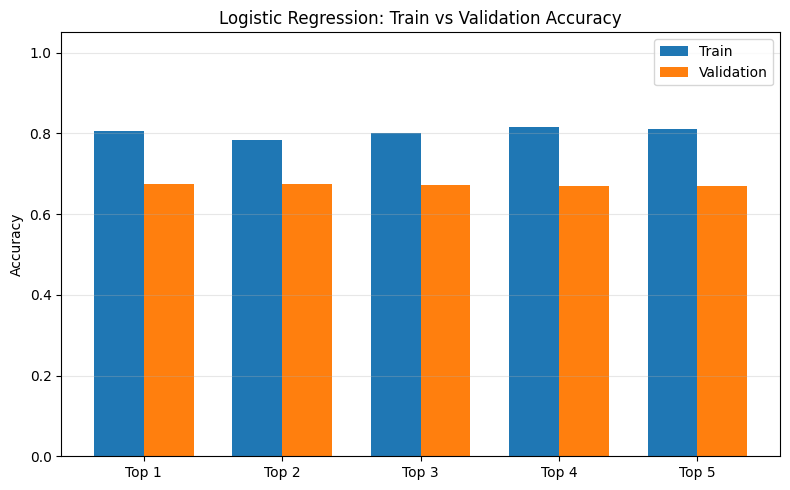

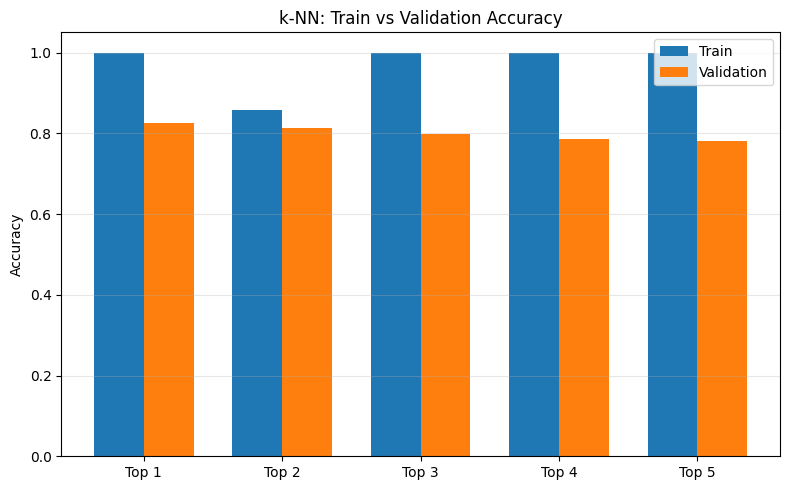

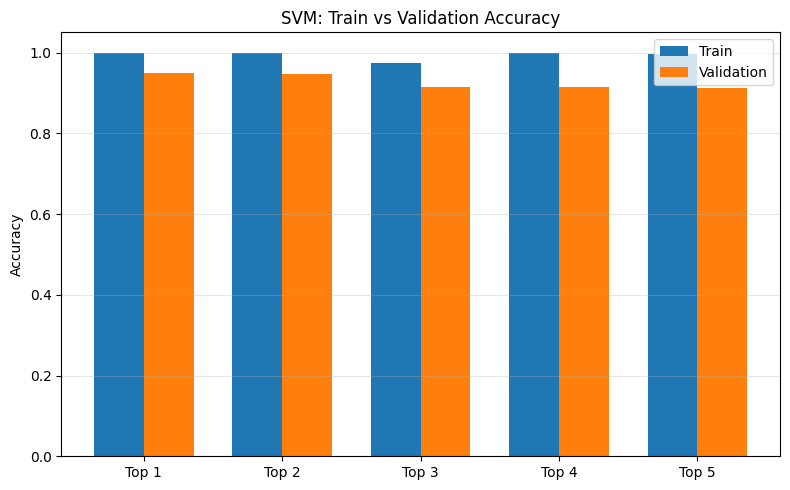

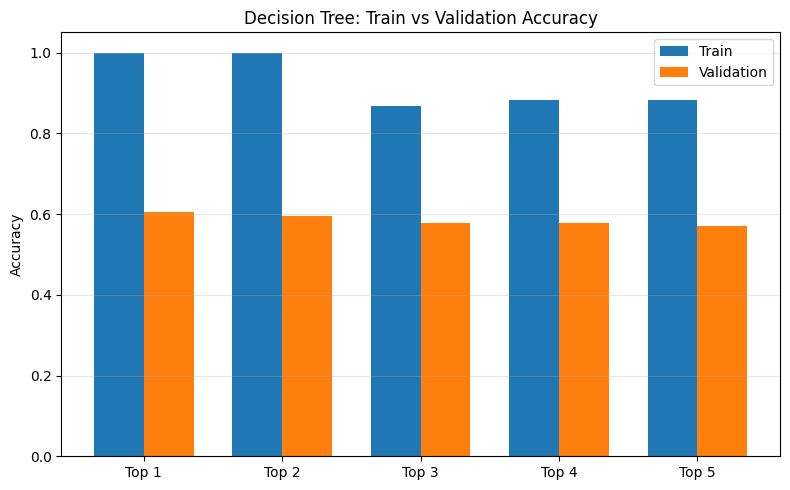

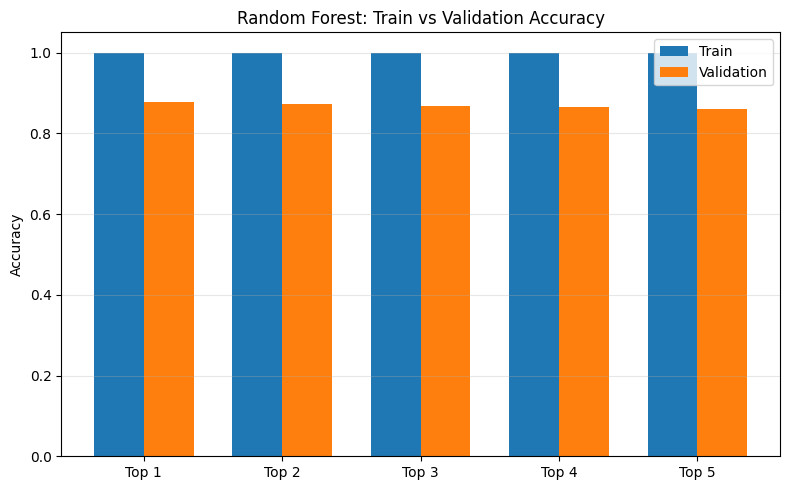

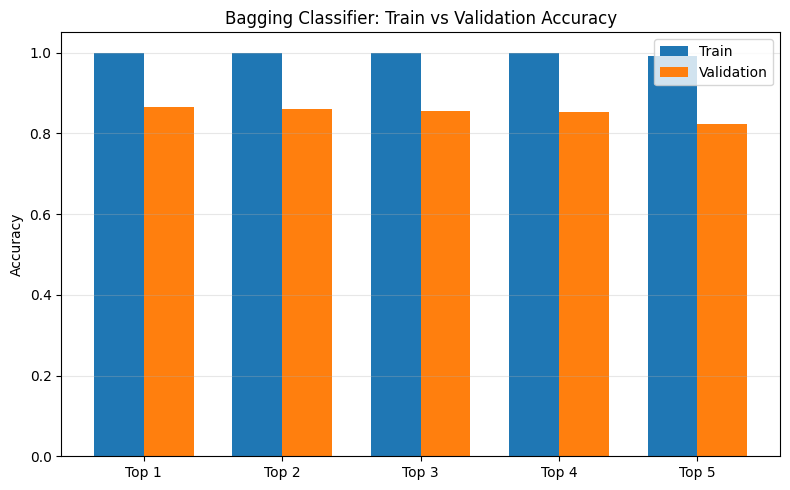

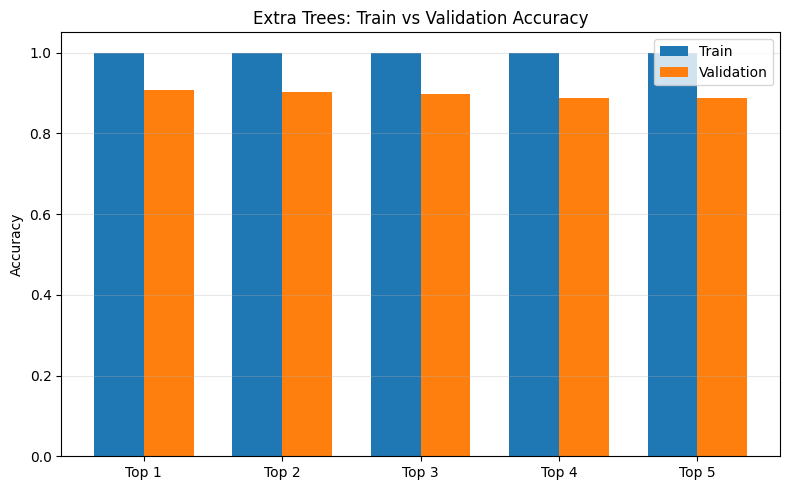

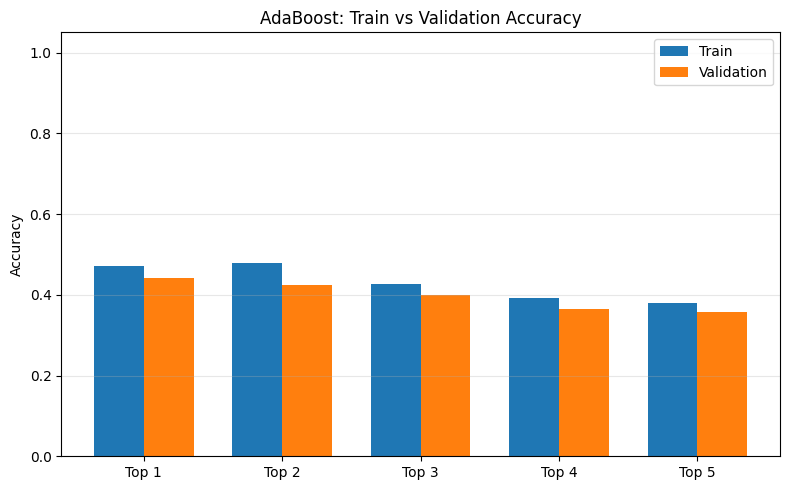

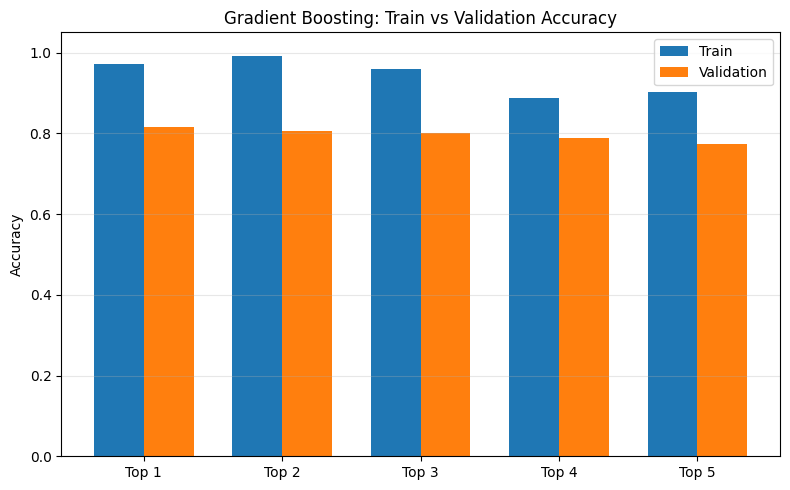

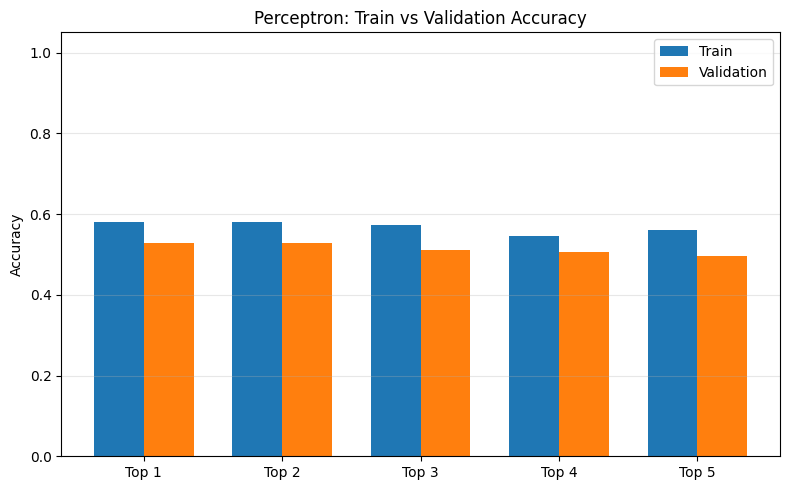

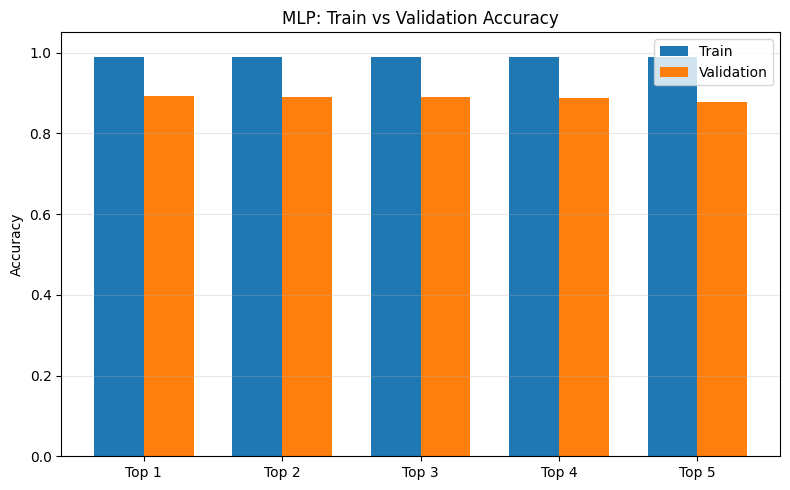

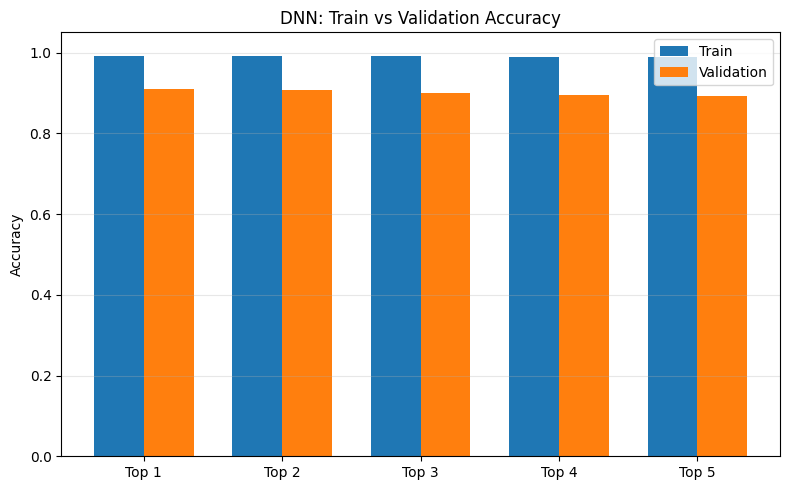

Saved 12 model accuracy plots to C:\Users\sjune\OneDrive\바탕 화면\대학(3-2)\기계학습\VegetableClassification\model_accuracy_plots


In [51]:
import matplotlib.pyplot as plt

plot_output_dir = Path("model_accuracy_plots")
plot_output_dir.mkdir(exist_ok=True)

for model_name, candidates in best_five_parameters.items():
    ranks = np.arange(1, len(candidates) + 1)
    train_accuracies = [candidate["train_accuracy"] for candidate in candidates]
    validation_accuracies = [candidate["validation_accuracy"] for candidate in candidates]
    bar_width = 0.36

    figure, axis = plt.subplots(figsize=(8, 5))
    axis.bar(ranks - bar_width / 2, train_accuracies, bar_width, label="Train")
    axis.bar(ranks + bar_width / 2, validation_accuracies, bar_width, label="Validation")
    axis.set_xticks(ranks, [f"Top {rank}" for rank in ranks])
    axis.set_ylim(0, 1.05)
    axis.set_ylabel("Accuracy")
    axis.set_title(f"{model_name}: Train vs Validation Accuracy")
    axis.legend()
    axis.grid(axis="y", alpha=0.3)
    figure.tight_layout()
    plot_path = plot_output_dir / f"{model_name.lower().replace(' ', '_')}_train_validation_accuracy.png"
    figure.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(figure)

print(f"Saved {len(best_five_parameters)} model accuracy plots to {plot_output_dir.resolve()}")

# Model Accuracy Comparison

In [50]:
final_comparison = {}
for model_name, candidates in best_five_parameters.items():
    mean_test_accuracy = float(np.mean([candidate["test_accuracy"] for candidate in candidates]))
    final_comparison[model_name] = mean_test_accuracy
    print(f"{model_name}: top-5 mean test accuracy = {mean_test_accuracy:.4f}")

print("\nModels ranked by top-5 mean test accuracy:")
for model_name, mean_accuracy in sorted(final_comparison.items(), key=lambda item: item[1], reverse=True):
    print(f"{model_name}: {mean_accuracy:.4f}")

Logistic Regression: top-5 mean test accuracy = 0.6699
k-NN: top-5 mean test accuracy = 0.8039
SVM: top-5 mean test accuracy = 0.9363
Decision Tree: top-5 mean test accuracy = 0.5793
Random Forest: top-5 mean test accuracy = 0.8782
Bagging Classifier: top-5 mean test accuracy = 0.8579
Extra Trees: top-5 mean test accuracy = 0.9016
AdaBoost: top-5 mean test accuracy = 0.4096
Gradient Boosting: top-5 mean test accuracy = 0.8011
Perceptron: top-5 mean test accuracy = 0.5047
MLP: top-5 mean test accuracy = 0.8948
DNN: top-5 mean test accuracy = 0.9059

Models ranked by top-5 mean test accuracy:
SVM: 0.9363
DNN: 0.9059
Extra Trees: 0.9016
MLP: 0.8948
Random Forest: 0.8782
Bagging Classifier: 0.8579
k-NN: 0.8039
Gradient Boosting: 0.8011
Logistic Regression: 0.6699
Decision Tree: 0.5793
Perceptron: 0.5047
AdaBoost: 0.4096
